# Task 1 – Uber fare prediction (Linear Regression vs Random Forest)

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import warnings; warnings.filterwarnings("ignore")

df = pd.read_csv("uber.csv")
print("Shape:", df.shape)
df.head()

Shape: (200000, 9)


,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [2]:
df.info()
print("\nMissing values:\n", df.isnull().sum())
df.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  str    
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  str    
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), str(2)
memory usage: 13.7 MB

Missing values:
 Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64


,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,200000.0,2.771250e+07,1.601382e+07,1.000000,1.382535e+07,2.774550e+07,4.155530e+07,5.542357e+07
fare_amount,200000.0,1.135996e+01,9.901776e+00,-52.000000,6.000000e+00,8.500000e+00,1.250000e+01,4.990000e+02
pickup_longitude,200000.0,-7.252764e+01,1.143779e+01,-1340.648410,-7.399206e+01,-7.398182e+01,-7.396715e+01,5.741846e+01
pickup_latitude,200000.0,3.993589e+01,7.720539e+00,-74.015515,4.073480e+01,4.075259e+01,4.076716e+01,1.644421e+03
dropoff_longitude,199999.0,-7.252529e+01,1.311741e+01,-3356.666300,-7.399141e+01,-7.398009e+01,-7.396366e+01,1.153573e+03
dropoff_latitude,199999.0,3.992389e+01,6.794829e+00,-881.985513,4.073382e+01,4.075304e+01,4.076800e+01,8.726976e+02
passenger_count,200000.0,1.684535e+00,1.385997e+00,0.000000,1.000000e+00,1.000000e+00,2.000000e+00,2.080000e+02


## 1. Pre-processing

In [3]:
df = df.drop(columns=["Unnamed: 0", "key"])           # ID columns, no predictive value
df = df.dropna()                                      # only 1 row has missing drop-off coordinates
df["pickup_datetime"] = pd.to_datetime(df["pickup_datetime"])

# time features
df["hour"]    = df["pickup_datetime"].dt.hour
df["day"]     = df["pickup_datetime"].dt.day
df["month"]   = df["pickup_datetime"].dt.month
df["year"]    = df["pickup_datetime"].dt.year
df["weekday"] = df["pickup_datetime"].dt.dayofweek
df = df.drop(columns="pickup_datetime")

# distance feature (Haversine, km) – lat/long alone do not predict the fare
def haversine(lon1, lat1, lon2, lat2):
    lon1, lat1, lon2, lat2 = map(np.radians, [lon1, lat1, lon2, lat2])
    a = np.sin((lat2-lat1)/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin((lon2-lon1)/2)**2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

df["distance_km"] = haversine(df.pickup_longitude, df.pickup_latitude, df.dropoff_longitude, df.dropoff_latitude)
print("Shape after cleaning:", df.shape)
df.head()

Shape after cleaning: (199999, 12)


,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,hour,day,month,year,weekday,distance_km
0,7.5,-73.999817,40.738354,-73.999512,40.723217,1,19,7,5,2015,3,1.683323
1,7.7,-73.994355,40.728225,-73.994710,40.750325,1,20,17,7,2009,4,2.457590
2,12.9,-74.005043,40.740770,-73.962565,40.772647,1,21,24,8,2009,0,5.036377
3,5.3,-73.976124,40.790844,-73.965316,40.803349,3,8,26,6,2009,4,1.661683
4,16.0,-73.925023,40.744085,-73.973082,40.761247,5,17,28,8,2014,3,4.475450


## 2. Identify outliers

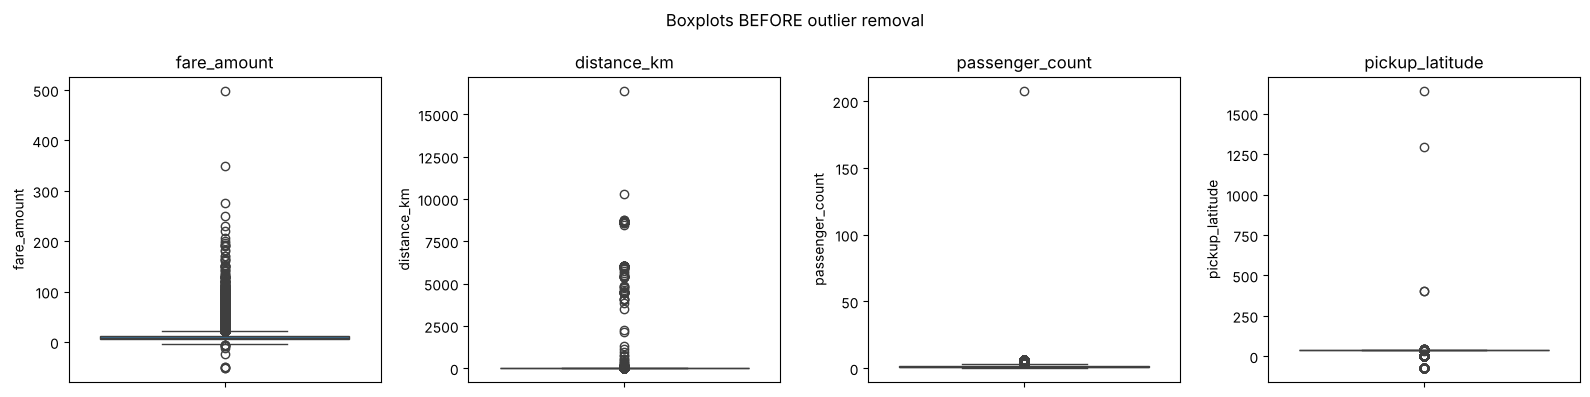

IQR outliers: fare = 17166 | distance = 16755
Impossible values: fare<=0 -> 22 | passengers==0 -> 708 | passengers>6 -> 1 | lat/long outside NYC box -> 4375


In [4]:
fig, ax = plt.subplots(1, 4, figsize=(16, 4))
for a, c in zip(ax, ["fare_amount", "distance_km", "passenger_count", "pickup_latitude"]):
    sns.boxplot(y=df[c], ax=a); a.set_title(c)
plt.suptitle("Boxplots BEFORE outlier removal"); plt.tight_layout(); plt.show()

def iqr_count(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return ((s < q1 - 1.5*i) | (s > q3 + 1.5*i)).sum()
print("IQR outliers: fare =", iqr_count(df.fare_amount), "| distance =", iqr_count(df.distance_km))
print("Impossible values: fare<=0 ->", (df.fare_amount <= 0).sum(),
      "| passengers==0 ->", (df.passenger_count == 0).sum(),
      "| passengers>6 ->", (df.passenger_count > 6).sum(),
      "| lat/long outside NYC box ->",
      (~(df.pickup_latitude.between(40.5, 41.0) & df.dropoff_latitude.between(40.5, 41.0) &
         df.pickup_longitude.between(-74.3, -73.6) & df.dropoff_longitude.between(-74.3, -73.6))).sum())

**Treatment**: remove physically impossible rows (invalid coordinates, fare ≤ 0, 0 or >6 passengers, zero distance), then cap extreme fares and distances using the IQR rule (1.5×IQR, which is a standard rule).

Removed invalid rows: 7047
IQR filter on fare_amount: removed 16466
IQR filter on distance_km: removed 7724
Final shape: (168762, 12)


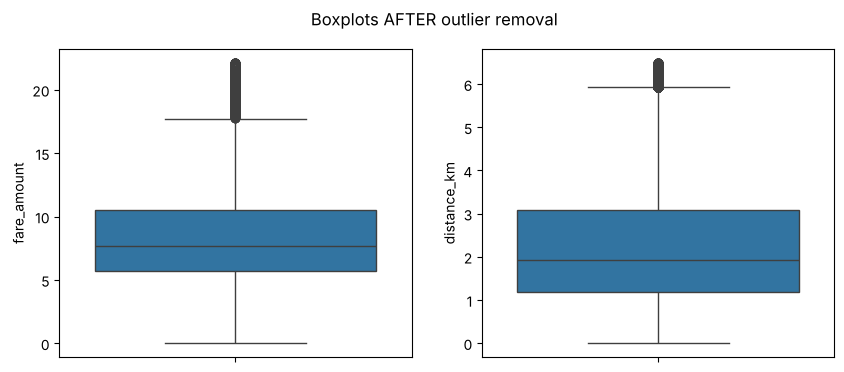

In [5]:
n0 = len(df)
df = df[(df.pickup_latitude.between(40.5, 41.0)) & (df.dropoff_latitude.between(40.5, 41.0)) &
        (df.pickup_longitude.between(-74.3, -73.6)) & (df.dropoff_longitude.between(-74.3, -73.6))]
df = df[(df.fare_amount > 0) & (df.passenger_count.between(1, 6)) & (df.distance_km > 0)]
print("Removed invalid rows:", n0 - len(df))

for c in ["fare_amount", "distance_km"]:
    q1, q3 = df[c].quantile([.25, .75]); i = q3 - q1
    n = len(df)
    df = df[df[c].between(q1 - 1.5*i, q3 + 1.5*i)]
    print(f"IQR filter on {c}: removed {n - len(df)}")
print("Final shape:", df.shape)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.boxplot(y=df.fare_amount, ax=ax[0]); sns.boxplot(y=df.distance_km, ax=ax[1])
plt.suptitle("Boxplots AFTER outlier removal"); plt.show()

## 3. Correlation

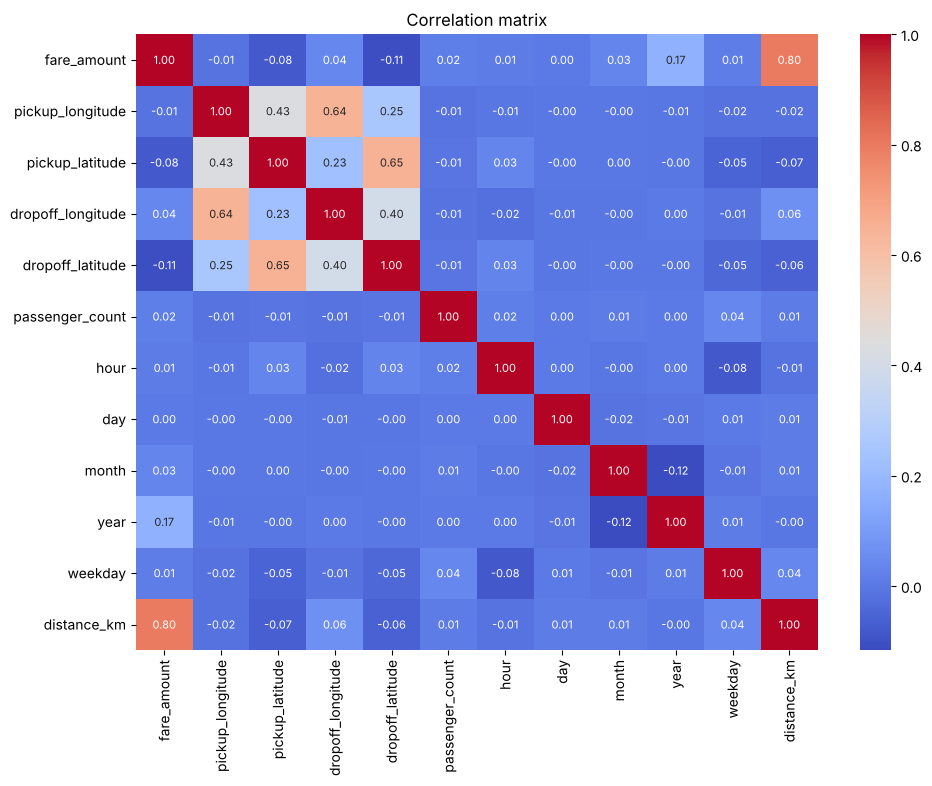

fare_amount          1.000
distance_km          0.795
year                 0.173
dropoff_longitude    0.037
month                0.033
passenger_count      0.017
weekday              0.013
hour                 0.007
day                  0.005
pickup_longitude    -0.015
pickup_latitude     -0.080
dropoff_latitude    -0.112
Name: fare_amount, dtype: float64


In [6]:
plt.figure(figsize=(11, 8))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", annot_kws={"size": 8})
plt.title("Correlation matrix"); plt.show()
print(df.corr()["fare_amount"].sort_values(ascending=False).round(3))

`distance_km` has by far the strongest correlation with the fare; `year` is the next strongest (fares rose over time). Raw latitude/longitude are weak.

## 4. Models

In [7]:
X = df.drop(columns="fare_amount")
y = df["fare_amount"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train:", X_train.shape, "Test:", X_test.shape)

lr = LinearRegression().fit(X_train, y_train)
lr_pred = lr.predict(X_test)

rf = RandomForestRegressor(n_estimators=100, max_depth=None, min_samples_leaf=2, n_jobs=-1, random_state=42)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)
print("Both models trained.")

Train: (135009, 11) Test: (33753, 11)


Both models trained.


## 5. Evaluation

In [8]:
def evaluate(name, y_true, y_pred, model=None, Xtr=None, ytr=None):
    return {"Model": name,
            "R2 (test)": r2_score(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "MAE": mean_absolute_error(y_true, y_pred),
            "MSE": mean_squared_error(y_true, y_pred),
            "R2 (train)": r2_score(ytr, model.predict(Xtr))}

res = pd.DataFrame([evaluate("Linear Regression", y_test, lr_pred, lr, X_train, y_train),
                    evaluate("Random Forest",     y_test, rf_pred, rf, X_train, y_train)]).set_index("Model").round(4)
res

,R2 (test),RMSE,MAE,MSE,R2 (train)
Model,,,,,
Linear Regression,0.6722,2.1203,1.5159,4.4958,0.6701
Random Forest,0.7485,1.8573,1.2863,3.4497,0.9416


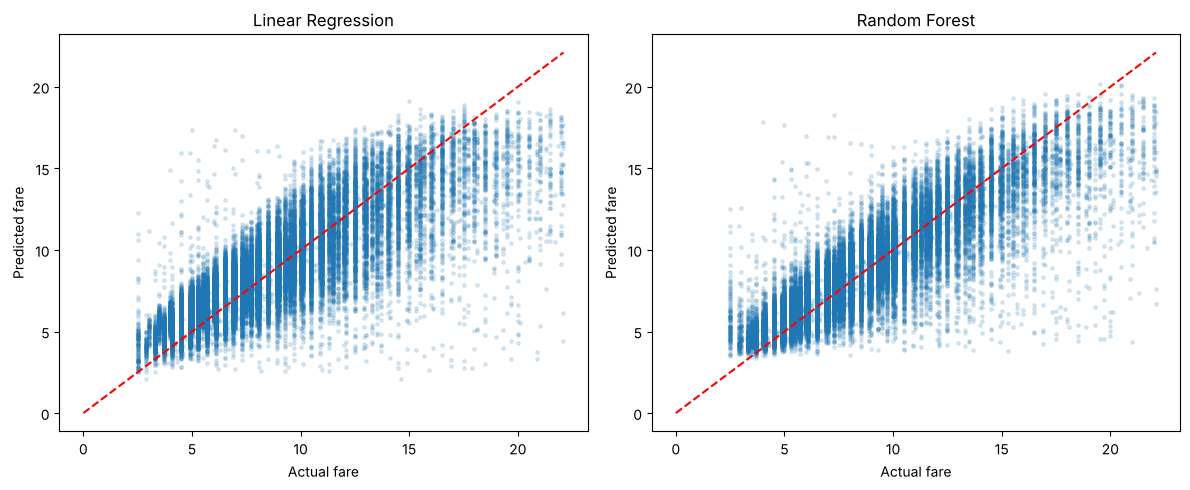

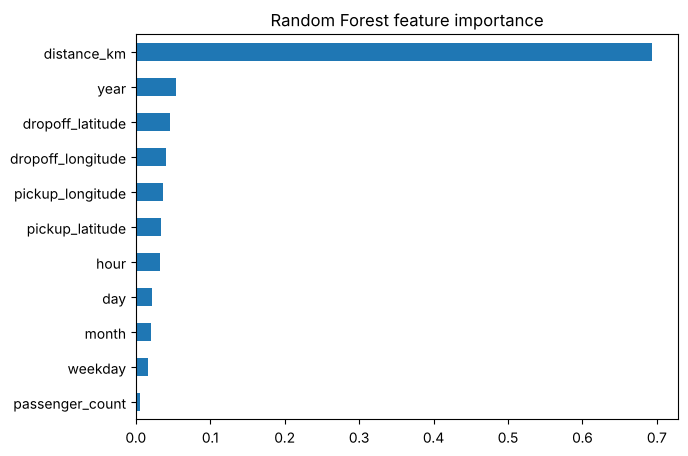

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for a, (n, p) in zip(ax, [("Linear Regression", lr_pred), ("Random Forest", rf_pred)]):
    a.scatter(y_test, p, alpha=0.15, s=6)
    a.plot([0, y.max()], [0, y.max()], "r--"); a.set_xlabel("Actual fare"); a.set_ylabel("Predicted fare"); a.set_title(n)
plt.tight_layout(); plt.show()

imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
imp.plot.barh(figsize=(7, 5), title="Random Forest feature importance"); plt.show()

## Conclusion
- Random Forest beats Linear Regression on every test metric: R² 0.7485 vs 0.6722, RMSE 1.86 vs 2.12, MAE 1.29 vs 1.52.
- The fare is not perfectly linear in distance (base fare, surcharges, traffic, flat airport rates), and the forest captures those non-linear effects and interactions.
- The main driver is `distance_km` (correlation 0.795 with fare), then `year`.
- The forest overfits: train R² is 0.94 but test R² is 0.75. To reduce this, limit `max_depth`, raise `min_samples_leaf`, or tune with cross-validation.
- Missing information (traffic, exact route, tolls, surge pricing) caps how accurate any model can get from this data.